# 03 - Assignment visualisations (CSIT 750, part c)

This notebook draws the three figures for the research-methodology assignment from the **synthetic dataset**
created by `src/generate_data.py` (96 channels, 8 reach directions, 800 trials, seed 0).

| Figure | Chart type | Question it answers |
|---|---|---|
| 1 | Tuning curves (line + points with error bars) | Does each neuron prefer one direction, as in real motor cortex? |
| 2 | Heatmap (neurons x directions) | Does the whole population carry enough information to tell directions apart? |
| 3 | Spike raster + time-course line chart | What does the decoder actually receive, and when does direction information appear? |

The same figures are saved as PNG files in `results/figures/`. All the plotting code is in `src/part_c_outputs.py`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import generate_data as gd
import part_c_outputs as pc

cfg = pc.assignment_config()
data = gd.generate_dataset(cfg)
print("Dataset:", data["spikes"].shape, "(trials, channels, time bins)")

Dataset: (800, 96, 100) (trials, channels, time bins)


## The dataset in numbers

In [2]:
import pandas as pd
summary = pc.dataset_summary(data)
pd.Series(summary).to_frame("value")

,value
trials,800
channels,96
time_bins,100
bin_ms,10.0
trial_duration_s,1.0
silent_channels,20
active_channels,76
trials_per_direction,100
train_val_test,"[560, 120, 120]"
overall_mean_rate_hz,9.657669


## Figure 1 - Tuning curves

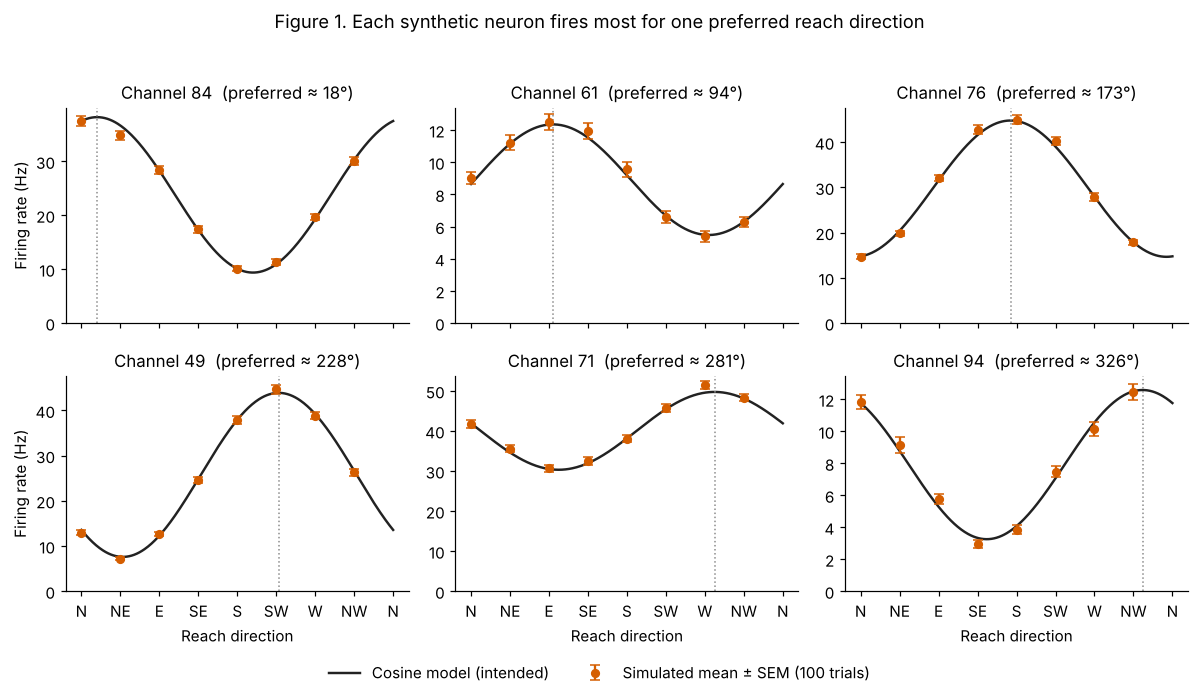

Correlation between intended and simulated rates (all active neurons x 8 directions): 0.9995


In [3]:
fig1, s1 = pc.figure1_tuning_curves(data)
plt.show()
print("Correlation between intended and simulated rates (all active neurons x 8 directions):",
      round(s1["corr_intended_vs_measured"], 4))

## Figure 2 - Population heatmap

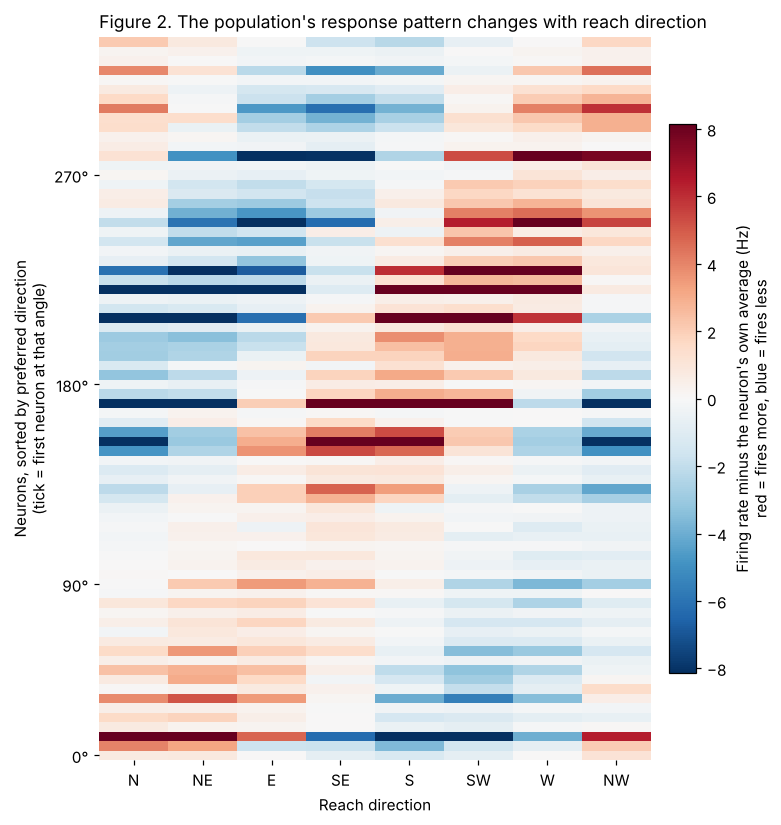

Share of neurons whose strongest direction is within 45 deg of their true preferred direction: 0.908
... among the stronger-tuned half: 1.0


In [4]:
fig2, s2 = pc.figure2_population_heatmap(data)
plt.show()
print("Share of neurons whose strongest direction is within 45 deg of their true preferred direction:",
      round(s2["share_peak_within_45deg_all"], 3))
print("... among the stronger-tuned half:", round(s2["share_peak_within_45deg_strong_half"], 3))

## Figure 3 - Raster and time course

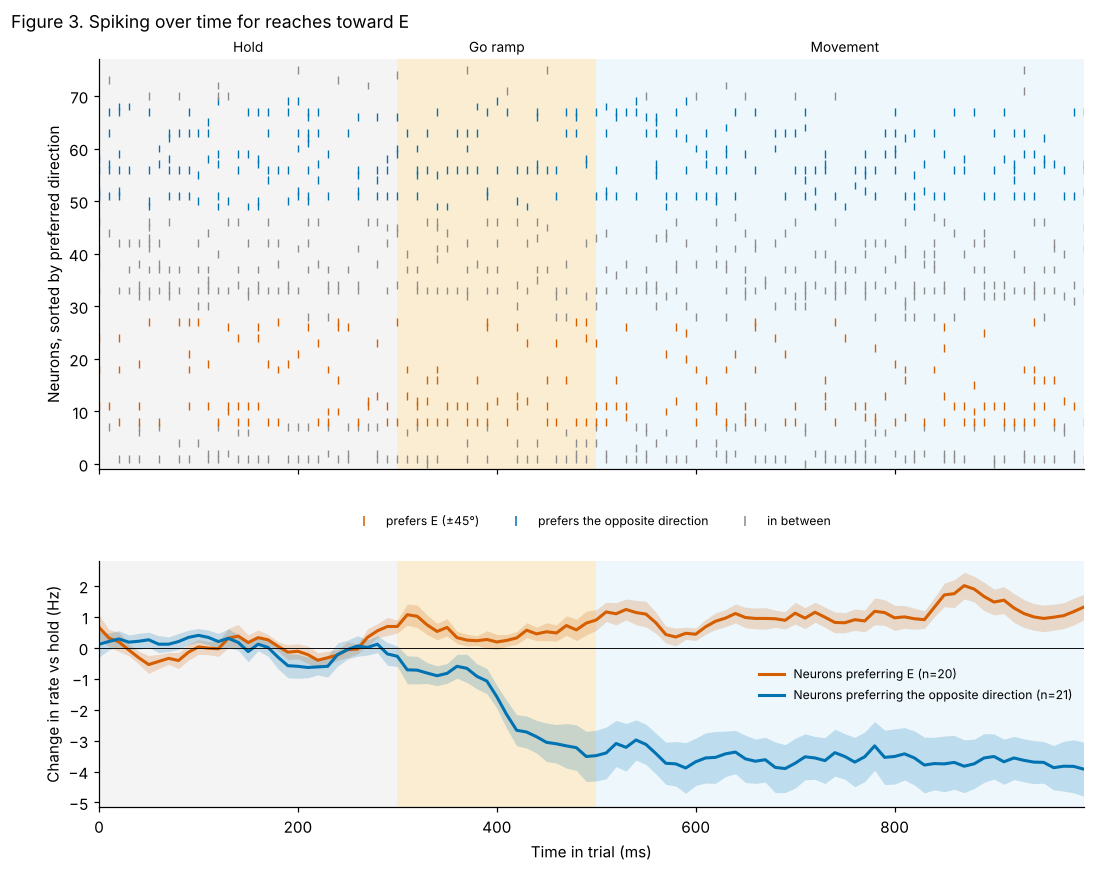

{'example_trial_id': 2, 'direction': 'E', 'n_preferring': 20, 'n_opposite': 21, 'preferring_change_movement_hz': 1.07, 'opposite_change_movement_hz': -3.59, 'preferring_change_hold_hz': 0.01, 'opposite_change_hold_hz': -0.01, 'spikes_in_example_trial': 913}


In [5]:
fig3, s3 = pc.figure3_raster_and_psth(data)
plt.show()
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in s3.items()})

## Save everything

Running the next cell rewrites the PNG files in `results/figures/`, the CSV files in `data/synthetic/assignment_dataset/`
and the numbers in `results/tables/part_c_summary_stats.json`.

In [6]:
_ = pc.build_everything(save=True)
plt.close("all")   # figures were already shown above
print("Saved.")

Saved.
